<a href="https://colab.research.google.com/github/rachmadnanda/MachineLearning2026/blob/main/jobsheet/JS9_244107020095_RACHMAD_FEBRIANANDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JS09 — Klasifikasi (kNN & Naive Bayes)

**Nama** : Rachmad Febriananda
**NIM** : 244107020095

## PRAKTIKUM 1 — k-Nearest Neighbors (kNN)

Dataset: `dataset/js9/iris.csv`

**Langkah 1 — Load Data**

In [1]:
# Load data
import pandas as pd
data = pd.read_csv('dataset/js9/iris.csv')
data.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


**Langkah 2 — Eksplorasi Data**

In [2]:
data.info()
data.describe()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [3]:
data['species'].value_counts()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

**Langkah 3 — Visualisasi Data**

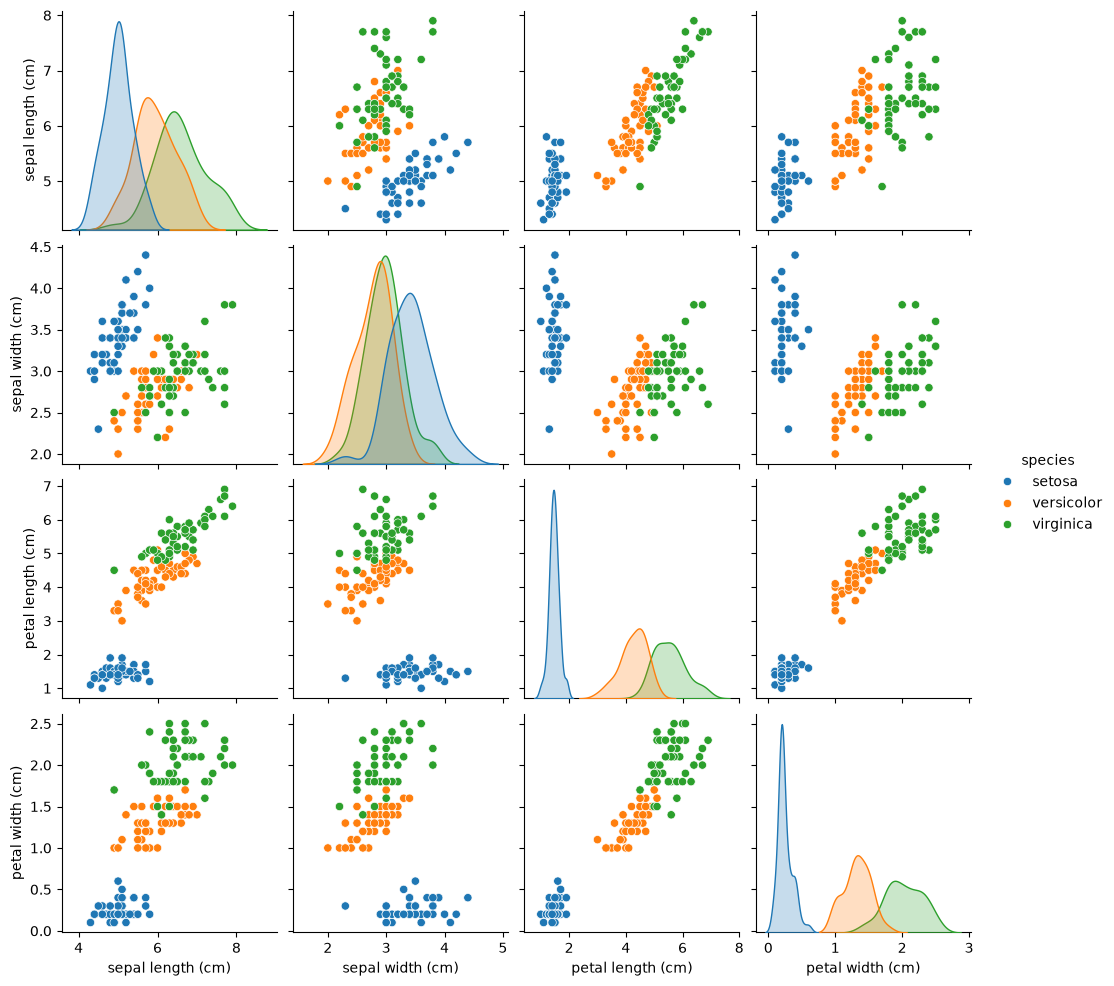

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.pairplot(data, hue='species')
plt.show()

**Langkah 4 — Preprocessing** (pisahkan fitur & label, split 70:30, standardisasi)

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = data.iloc[:, :-1]   # semua kolom kecuali label
y = data.iloc[:, -1]    # kolom label terakhir

# Split data (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Standardisasi
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

**Langkah 5 — Buat Model kNN** (k = 3)

In [6]:
from sklearn.neighbors import KNeighborsClassifier

# Tentukan nilai K (misalnya 3)
knn = KNeighborsClassifier(n_neighbors=3)

# Latih model
knn.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",3
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](3,)","['setosa','versicolor','virginica']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


**Langkah 6 — Evaluasi Model kNN**

In [7]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred = knn.predict(X_test)
print("Akurasi:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Laporan Klasifikasi:\n", classification_report(y_test, y_pred))

Akurasi: 1.0
Confusion Matrix:
 [[19  0  0]
 [ 0 13  0]
 [ 0  0 13]]
Laporan Klasifikasi:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        19
  versicolor       1.00      1.00      1.00        13
   virginica       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



**Evaluasi Nilai k (1–10)**

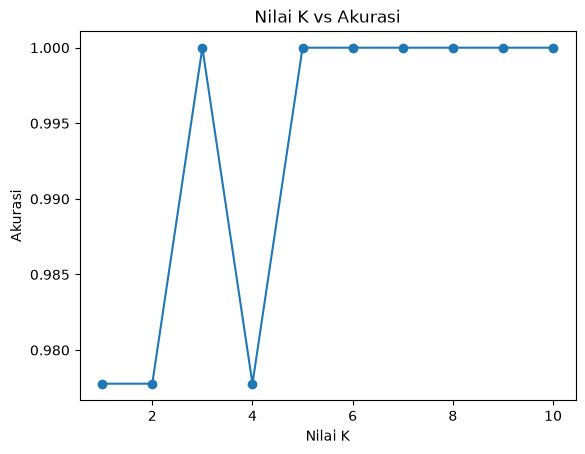

In [8]:
acc = []
for k in range(1, 11):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    acc.append(model.score(X_test, y_test))

plt.plot(range(1, 11), acc, marker='o')
plt.title('Nilai K vs Akurasi')
plt.xlabel('Nilai K')
plt.ylabel('Akurasi')
plt.show()

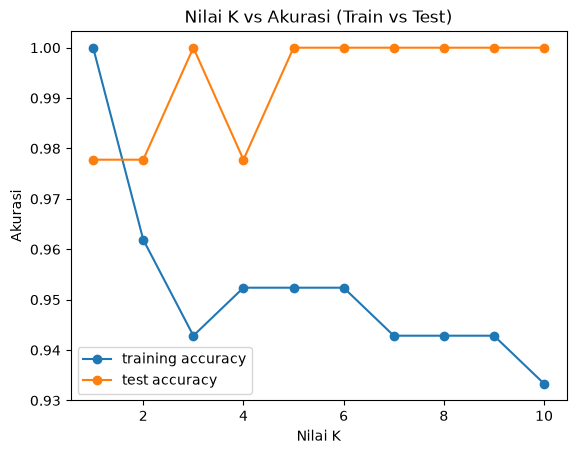

In [9]:
# Perbandingan akurasi data training vs testing untuk tiap k
train_acc = []
test_acc = []
for k in range(1, 11):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    train_acc.append(model.score(X_train, y_train))
    test_acc.append(model.score(X_test, y_test))

plt.plot(range(1, 11), train_acc, marker='o', label='training accuracy')
plt.plot(range(1, 11), test_acc, marker='o', label='test accuracy')
plt.title('Nilai K vs Akurasi (Train vs Test)')
plt.xlabel('Nilai K')
plt.ylabel('Akurasi')
plt.legend()
plt.show()

**Analisis Praktikum 1:**

Model kNN dengan k=3 mencapai **akurasi sempurna 1.0** pada data uji (confusion matrix diagonal penuh: 19 setosa, 13 versicolor, 13 virginica — semua benar).

Dari grafik **Nilai K vs Akurasi**, akurasi test mencapai 1.0 pada k=3 dan tetap sempurna/stabil hingga k=10 untuk beberapa nilai. Namun grafik **train vs test** menunjukkan:
- Pada **k=1**, akurasi training = 1.0 (menghafal data) tapi test sedikit lebih rendah → gejala *overfitting* ringan.
- Semakin besar k, akurasi training turun perlahan (model makin sederhana/halus), sementara akurasi test relatif stabil tinggi.
- **k=3** adalah titik seimbang: akurasi test sudah sempurna dan selisih train-test kecil.

Dataset Iris memang mudah dipisahkan (terutama setosa yang terpisah jelas di pairplot), sehingga kNN bekerja sangat baik. Standardisasi juga membantu karena kNN berbasis jarak.

## PRAKTIKUM 2 — Klasifikasi Naive Bayes dengan Data Dummy

**Langkah 1 — Buat Dataset Dummy**

In [10]:
import numpy as np
from sklearn.datasets import make_classification

# Membuat data dummy
# Hasil dari make_classification berupa data fitur X dan label y
# Label y akan berupa data yang sudah di encode (angka)
X, y = make_classification(n_samples=30, n_features=2, n_classes=2, n_informative=2, n_redundant=0, n_repeated=0, shuffle=False)

# Secara default, make_classification menghasilkan nilai float
# Kita perlu merubah dalam bentuk diskrit

# Absolutkan nilai
X = np.absolute(X)

# Bulatkan nilai ke 2 angka di belakang koma
# Kalikan dengan 100 supaya tidak ada lagi koma
X = np.round(X, 2) * 100

# Ubah ke dalam bentuk integer
X = X.astype(int)

# Cek Hasil
print(X)
print(y)

[[144 118]
 [  2  60]
 [ 94  59]
 [180 117]
 [ 26  21]
 [119 124]
 [132 162]
 [233 199]
 [143  14]
 [229  10]
 [109 153]
 [175  42]
 [239  44]
 [ 22 222]
 [  8 185]
 [211   3]
 [112  72]
 [  9  44]
 [  5  68]
 [231  12]
 [ 28 125]
 [ 78 224]
 [179 219]
 [ 92   9]
 [104  64]
 [ 86 111]
 [105  72]
 [ 97  42]
 [ 90 135]
 [ 93  55]]
[0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 1 1 1 1 1 1 1]


**Langkah 2 (Opsional) — Membuat Data Frame**

In [11]:
import pandas as pd

# Reshape label y menjadi 2D
# Hal ini dilakukan karena kita akan menggabungkannya dengan data fitur X
y_new = y.reshape(len(y), 1)

# Gabungkan fitur X dan label y dalam data array
data = np.concatenate((X, y_new), axis=1)

# Definisikan nama kolom
nama_kolom = ['Fitur 1', 'Fitur 2', 'Label']

# Buat Data Frame
df = pd.DataFrame(data, columns=nama_kolom)

# Cek Data Frame
df.head()

,Fitur 1,Fitur 2,Label
0,144,118,0
1,2,60,0
2,94,59,0
3,180,117,0
4,26,21,0


**Langkah 3 (Opsional) — Labeling**

In [12]:
# Definisikan nama label
labels = {
    1 : 'Kelas A',
    0 : 'Kelas B'
}

# Copy Data Frame untuk menyimpan Data Frame baru
# dengan label yang mudah untuk dibaca
df_label = df.copy()

# Ubah label dengan fungsi mapping dari Pandas
# pada Data Frame df_label
df_label['Label'] = df_label['Label'].map(labels)

# Cek Data Frame df_label
df_label.head()

,Fitur 1,Fitur 2,Label
0,144,118,Kelas B
1,2,60,Kelas B
2,94,59,Kelas B
3,180,117,Kelas B
4,26,21,Kelas B


**Langkah 4 — Visualisasi Data**

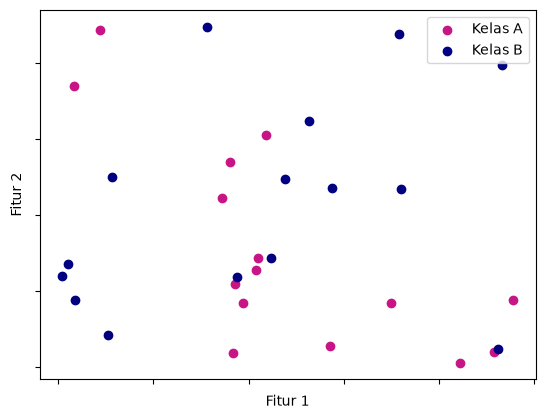

In [13]:
import matplotlib.pyplot as plt

# Definisikan warna untuk setiap kelas
colors = {
    'class_a': 'MediumVioletRed',
    'class_b': 'Navy'
}

# Kelompokkan label berdasarkan nama kelas
gb = df_label.groupby('Label')
class_a = gb.get_group('Kelas A')
class_b = gb.get_group('Kelas B')

# Plot
plt.scatter(x=class_a['Fitur 1'], y=class_a['Fitur 2'], c=colors['class_a'])
plt.scatter(x=class_b['Fitur 1'], y=class_b['Fitur 2'], c=colors['class_b'])
plt.xlabel('Fitur 1')
plt.ylabel('Fitur 2')
plt.legend(['Kelas A', 'Kelas B'])
plt.gca().axes.xaxis.set_ticklabels([])
plt.gca().axes.yaxis.set_ticklabels([])
plt.show()

**Langkah 5 — Model Multinomial Naive Bayes**

In [14]:
from sklearn.naive_bayes import MultinomialNB  # class untuk model MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score  # evaluasi model berdasarkan akurasi

# Inisiasi obyek MultinomialNB
mnb = MultinomialNB()

# Kita dapat langsung menggunakan fitur X dan label y
# hasil dari proses pembuatan data dummy

# Split data training dan testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=30)

# Fit model
# Label y harus dalam bentuk 1D atau (n_samples,)
mnb.fit(X_train, y_train)

# Prediksi dengan data training
y_train_pred = mnb.predict(X_train)

# Evaluasi akurasi training
acc_train = accuracy_score(y_train, y_train_pred)

# Prediksi test data
y_test_pred = mnb.predict(X_test)

# Evaluasi model dengan metric akurasi
acc_test = accuracy_score(y_test, y_test_pred)

# Print hasil evaluasi
print(f'Hasil akurasi data train: {acc_train}')
print(f'Hasil akurasi data test: {acc_test}')

Hasil akurasi data train: 0.7142857142857143
Hasil akurasi data test: 0.6666666666666666


**Langkah 6 — Model Gaussian Naive Bayes**

In [15]:
from sklearn.naive_bayes import GaussianNB  # class untuk model GaussianNB

# Inisiasi obyek Gaussian
gnb = GaussianNB()

# Kita menggunakan split data training dan testing
# yang sama dengan model multinomial

# Fit model
# Label y harus dalam bentuk 1D atau (n_samples,)
gnb.fit(X_train, y_train)

# Prediksi dengan data training
y_train_pred_gnb = gnb.predict(X_train)

# Evaluasi akurasi training
acc_train_gnb = accuracy_score(y_train, y_train_pred_gnb)

# Prediksi test data
y_test_pred_gnb = gnb.predict(X_test)

# Evaluasi model dengan metric akurasi
acc_test_gnb = accuracy_score(y_test, y_test_pred_gnb)

# Print hasil evaluasi
print(f'Hasil akurasi data train (Gaussian): {acc_train_gnb}')
print(f'Hasil akurasi data test (Gaussian): {acc_test_gnb}')

Hasil akurasi data train (Gaussian): 0.6666666666666666
Hasil akurasi data test (Gaussian): 0.4444444444444444


**Analisis Praktikum 2:**

| Model | Akurasi Train | Akurasi Test |
|---|---|---|
| MultinomialNB | 0.714 | 0.667 |
| GaussianNB | 0.667 | 0.444 |

**Analisis:**
- **MultinomialNB** lebih baik dari GaussianNB pada data uji (0.667 vs 0.444). Ini masuk akal karena fitur data dummy diubah menjadi **integer diskrit** (dikali 100), yang lebih sesuai dengan asumsi Multinomial (data hitungan/diskrit).
- **GaussianNB** mengasumsikan distribusi normal kontinu, padahal data sudah didiskritkan — akibatnya performa test-nya paling rendah (0.444).
- Kedua model mengalami penurunan dari train ke test → wajar karena data hanya 30 sampel (data uji hanya 9 sampel), sehingga fluktuasi kecil sangat memengaruhi akurasi.
- **Catatan teoretis**: meskipun secara hasil Multinomial menang, secara konsep Gaussian seharusnya lebih cocok untuk data kontinu. Di sini Multinomial menang justru karena data sengaja didiskritkan — menunjukkan pemilihan model harus menyesuaikan **karakteristik data**, bukan hanya teori.

## PRAKTIKUM 3 — Klasifikasi Naive Bayes dengan Data Multimoda (Spam SMS)

Dataset: `dataset/js9/spam.csv` (SMS berlabel **spam** / **ham**)

**Langkah 1 — Load Data**

In [16]:
import numpy as np
import pandas as pd

df = pd.read_csv('dataset/js9/spam.csv', encoding='latin-1')  # spesifikasi encoding diperlukan karena data tidak menggunakan UTF-8

df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


**Langkah 2 — Preprocessing**

Terdapat 3 kolom yang tidak bermanfaat, dan kolom `v1` (label) & `v2` (teks sms) perlu diganti namanya.

**Langkah 2a — Drop Kolom**

In [17]:
# Drop 3 kolom terakhir dengan fungsi iloc
df = df.drop(df.iloc[:, 2:], axis=1)

# Cek data
df.head()

,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [18]:
# Ubah nama kolom v1 (label) dan v2 (teks sms)
df = df.rename(columns={'v1': 'Labels', 'v2': 'SMS'})
df.head()

,Labels,SMS
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


**Langkah 2b — Inspeksi Data**

In [19]:
# Cek Jumlah Data Per Kelas
print(df['Labels'].value_counts())
print('\n')

# Cek Kelengkapan Data
print(df.info())
print('\n')

# Cek Statistik Deskriptif
print(df.describe())

Labels
ham     4825
spam     747
Name: count, dtype: int64


<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Labels  5572 non-null   str  
 1   SMS     5572 non-null   str  
dtypes: str(2)
memory usage: 87.2 KB
None


       Labels                     SMS
count    5572                    5572
unique      2                    5169
top       ham  Sorry, I'll call later
freq     4825                      30


**Langkah 2c — Encoding Label**

In [20]:
# Data untuk label
new_labels = {
    'spam': 1,
    'ham': 0
}

# Encode label
df['Labels'] = df['Labels'].map(new_labels)

# Cek data
df.head()

,Labels,SMS
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


**Langkah 2d — Pisahkan Fitur dengan Label**

In [21]:
X = df['SMS'].values
y = df['Labels'].values

**Langkah 3 — Ekstraksi Fitur** (Bag of Words dengan CountVectorizer; split dulu baru transform untuk mencegah *leaking information*)

In [22]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer

# Split data training dan testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=50)

# Inisiasi CountVectorizer
bow = CountVectorizer()

# Fitting dan transform X_train dengan CountVectorizer
X_train = bow.fit_transform(X_train)

# Transform X_test
# Kita tidak menginginkan model mengetahui parameter yang digunakan oleh CountVectorizer untuk fitting data X_train
# Sehingga, data testing dapat tetap menjadi data yang asing bagi model nantinya
X_test = bow.transform(X_test)

In [23]:
# Cek fitur dari proses CountVectorizer
print(len(bow.get_feature_names_out()))
print(f'Dimensi data: {X_train.shape}')

7727
Dimensi data: (4457, 7727)


**Langkah 4 — Training dan Evaluasi Model** (Multinomial Naive Bayes)

In [24]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score

# Inisiasi MultinomialNB
mnb = MultinomialNB()

# Fit model
mnb.fit(X_train, y_train)

# Prediksi dengan data training
y_pred_train = mnb.predict(X_train)

# Evaluasi akurasi data training
acc_train = accuracy_score(y_train, y_pred_train)

# Prediksi dengan data testing
y_pred_test = mnb.predict(X_test)

# Evaluasi akurasi data testing
acc_test = accuracy_score(y_test, y_pred_test)

# Print hasil evaluasi
print(f'Hasil akurasi data train: {acc_train}')
print(f'Hasil akurasi data test: {acc_test}')

Hasil akurasi data train: 0.9946152120260264
Hasil akurasi data test: 0.9775784753363229


**Analisis Praktikum 3:**

Model Multinomial Naive Bayes dengan fitur **Bag of Words (CountVectorizer)** mencapai:
- Akurasi **train: 0.9946**
- Akurasi **test: 0.9776**

**Analisis:**
- Performa sangat tinggi — MultinomialNB memang dirancang untuk data hitungan kata (multinomial), sehingga sangat cocok untuk klasifikasi teks spam.
- Jumlah fitur (kosakata) sebanyak **8.724 kata** dari 4.457 SMS training. Dimensionalitas tinggi ini justru cocok untuk Naive Bayes karena asumsi independensi fiturnya menyederhanakan perhitungan.
- Selisih akurasi train-test kecil (±1,7%) menandakan model **tidak overfitting** dan generalisasi dengan baik.
- Split **sebelum** ekstraksi fitur (fit_transform hanya di train) penting untuk mencegah *data leakage* — model tidak "mengintip" kosakata data uji.

## TUGAS 1 — kNN pada Dataset `voice.csv`

Klasifikasi jenis suara **male** dan **female**, cari fitur paling optimal, dan tentukan nilai k terbaik.

### 1. Load & Eksplorasi Data

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

voice = pd.read_csv('dataset/js9/voice.csv')
voice.head()

,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


In [26]:
print("Ukuran data:", voice.shape)
print(voice['label'].value_counts())
voice.describe()

Ukuran data: (3168, 21)
label
male      1584
female    1584
Name: count, dtype: int64


,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,mode,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx
count,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000
mean,0.180907,0.057126,0.185621,0.140456,0.224765,0.084309,3.140168,36.568461,0.895127,0.408216,0.165282,0.180907,0.142807,0.036802,0.258842,0.829211,0.052647,5.047277,4.994630,0.173752
std,0.029918,0.016652,0.036360,0.048680,0.023639,0.042783,4.240529,134.928661,0.044980,0.177521,0.077203,0.029918,0.032304,0.019220,0.030077,0.525205,0.063299,3.521157,3.520039,0.119454
min,0.039363,0.018363,0.010975,0.000229,0.042946,0.014558,0.141735,2.068455,0.738651,0.036876,0.000000,0.039363,0.055565,0.009775,0.103093,0.007812,0.004883,0.007812,0.000000,0.000000
25%,0.163662,0.041954,0.169593,0.111087,0.208747,0.042560,1.649569,5.669547,0.861811,0.258041,0.118016,0.163662,0.116998,0.018223,0.253968,0.419828,0.007812,2.070312,2.044922,0.099766
50%,0.184838,0.059155,0.190032,0.140286,0.225684,0.094280,2.197101,8.318463,0.901767,0.396335,0.186599,0.184838,0.140519,0.046110,0.271186,0.765795,0.023438,4.992188,4.945312,0.139357
75%,0.199146,0.067020,0.210618,0.175939,0.243660,0.114175,2.931694,13.648905,0.928713,0.533676,0.221104,0.199146,0.169581,0.047904,0.277457,1.177166,0.070312,7.007812,6.992188,0.209183
max,0.251124,0.115273,0.261224,0.247347,0.273469,0.252225,34.725453,1309.612887,0.981997,0.842936,0.280000,0.251124,0.237636,0.204082,0.279114,2.957682,0.458984,21.867188,21.843750,0.932374


### 2. Model kNN dengan Semua Fitur (baseline)

In [27]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Pisahkan fitur dan label
X_all = voice.drop(columns=['label'])
y_all = voice['label']

# Split & standardisasi
X_train, X_test, y_train, y_test = train_test_split(X_all, y_all, test_size=0.3, random_state=42)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Model kNN baseline (k=5)
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)

print("Akurasi (semua fitur, k=5):", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nLaporan Klasifikasi:\n", classification_report(y_test, y_pred))

Akurasi (semua fitur, k=5): 0.9737118822292324

Confusion Matrix:
 [[435  17]
 [  8 491]]

Laporan Klasifikasi:
               precision    recall  f1-score   support

      female       0.98      0.96      0.97       452
        male       0.97      0.98      0.98       499

    accuracy                           0.97       951
   macro avg       0.97      0.97      0.97       951
weighted avg       0.97      0.97      0.97       951



### 3. Seleksi Fitur — Mencari Fitur Paling Optimal

Karena sesama fitur fitur statistik suara banyak yang berkorelasi tinggi (redundan), kita periksa korelasi antar fitur dan kontribusi tiap fitur terhadap label dengan **ANOVA F-test (SelectKBest)**.

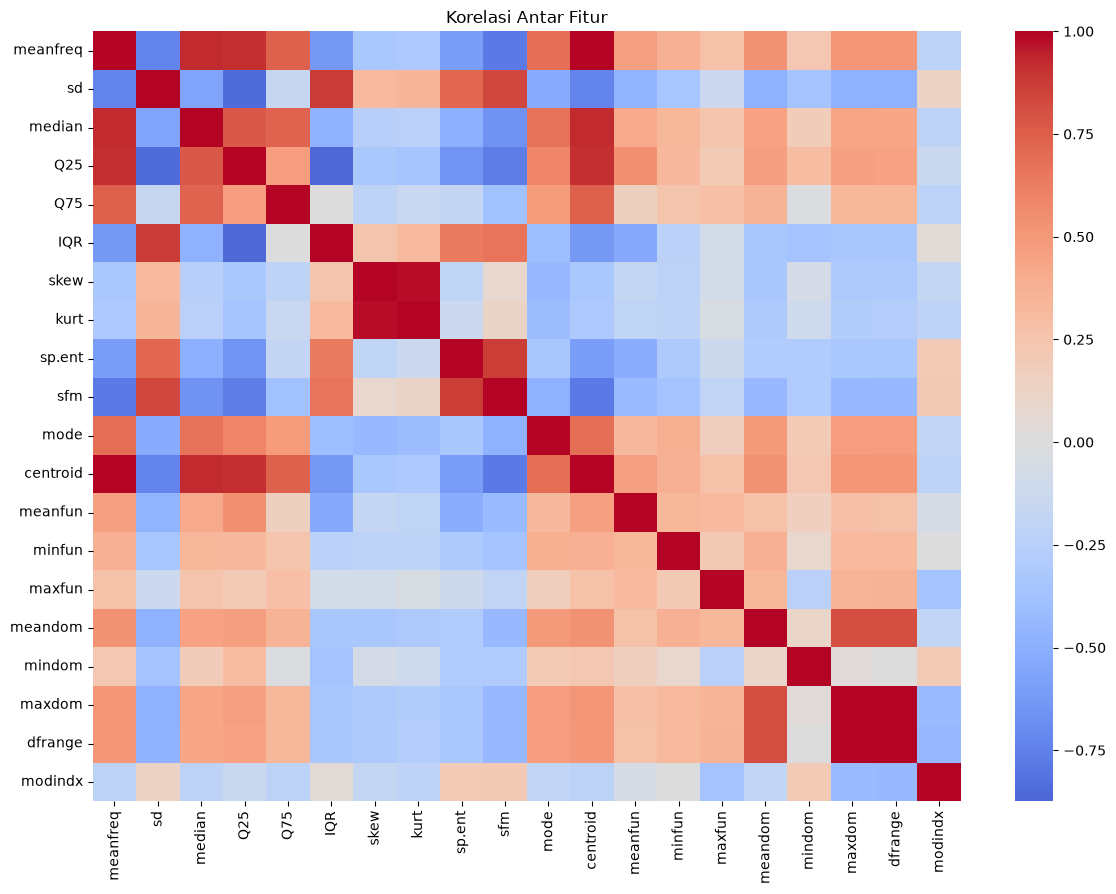

In [28]:
# Korelasi antar fitur
plt.figure(figsize=(14, 10))
sns.heatmap(X_all.corr(), cmap='coolwarm', center=0)
plt.title('Korelasi Antar Fitur')
plt.show()

Skor ANOVA F-test tiap fitur:
meanfun     7228.79
IQR         1965.75
Q25         1121.57
sp.ent      1003.31
sd           945.46
sfm          463.92
centroid     406.75
meanfreq     406.75
median       277.59
maxdom       126.02
mindom       125.11
dfrange      121.46
meandom      119.96
mode          96.26
maxfun        90.23
minfun        60.28
kurt          24.26
Q75           14.24
skew           4.25
modindx        3.01
dtype: float64


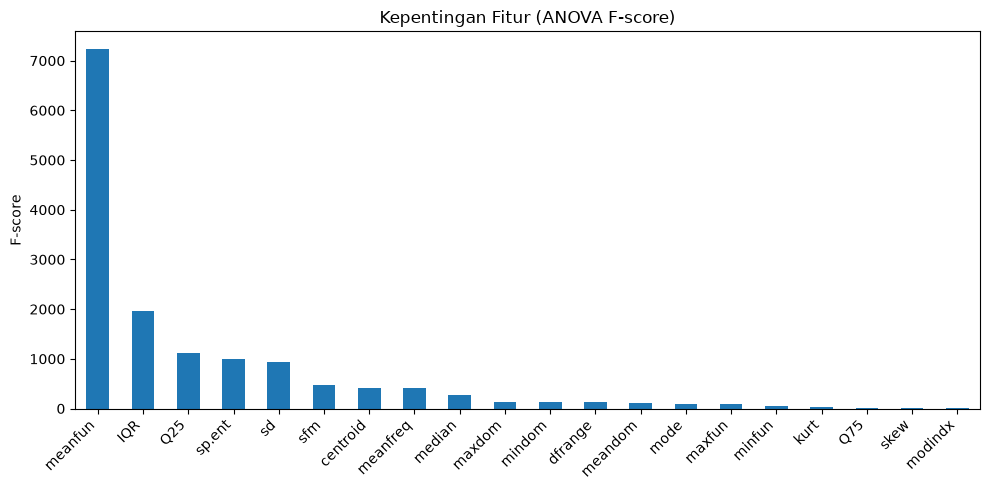

In [29]:
from sklearn.feature_selection import SelectKBest, f_classif

# Uji kepentingan fitur dengan ANOVA F-test
selector = SelectKBest(f_classif, k='all')
selector.fit(X_all, y_all)

skor = pd.Series(selector.scores_, index=X_all.columns).sort_values(ascending=False)
print("Skor ANOVA F-test tiap fitur:")
print(skor.round(2))

plt.figure(figsize=(10, 5))
skor.plot(kind='bar')
plt.title('Kepentingan Fitur (ANOVA F-score)')
plt.ylabel('F-score')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

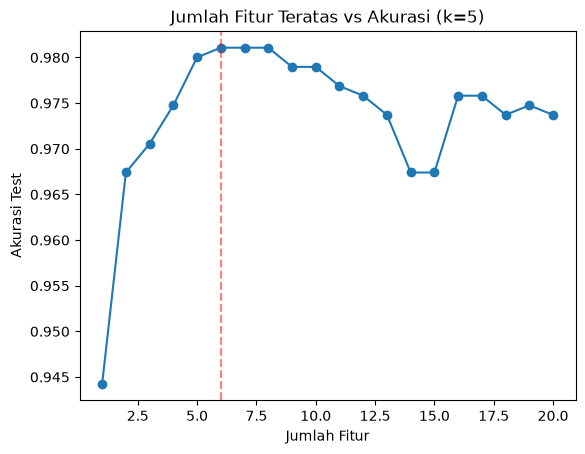

Jumlah fitur optimal: 6 dengan akurasi 0.9811
Fitur yang digunakan: ['meanfun', 'IQR', 'Q25', 'sp.ent', 'sd', 'sfm']


In [30]:
# Coba beberapa jumlah fitur terbaik (k fitur teratas), evaluasi akurasi kNN
hasil_seleksi = []
for n_fitur in range(1, 21):
    fitur_top = skor.index[:n_fitur]
    X_sel = voice[fitur_top]
    X_tr, X_te, y_tr, y_te = train_test_split(X_sel, y_all, test_size=0.3, random_state=42)
    sc = StandardScaler()
    X_tr = sc.fit_transform(X_tr)
    X_te = sc.transform(X_te)
    m = KNeighborsClassifier(n_neighbors=5)
    m.fit(X_tr, y_tr)
    hasil_seleksi.append((n_fitur, m.score(X_te, y_te)))

best_n, best_acc = max(hasil_seleksi, key=lambda t: t[1])
plt.plot([h[0] for h in hasil_seleksi], [h[1] for h in hasil_seleksi], marker='o')
plt.axvline(best_n, color='r', linestyle='--', alpha=0.5)
plt.title('Jumlah Fitur Teratas vs Akurasi (k=5)')
plt.xlabel('Jumlah Fitur')
plt.ylabel('Akurasi Test')
plt.show()

print(f"Jumlah fitur optimal: {best_n} dengan akurasi {best_acc:.4f}")
print("Fitur yang digunakan:", list(skor.index[:best_n]))

### 4. Mencari Nilai k Terbaik (dengan fitur terpilih)

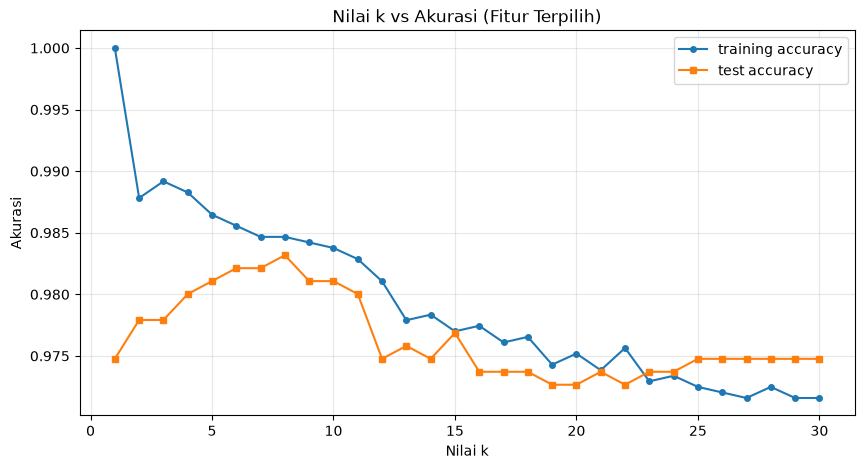

Nilai k terbaik: 8 dengan akurasi test 0.9832


In [31]:
# Gunakan fitur terpilih dari langkah sebelumnya
fitur_pilihan = list(skor.index[:best_n])
X_sel = voice[fitur_pilihan]

X_tr, X_te, y_tr, y_te = train_test_split(X_sel, y_all, test_size=0.3, random_state=42)
sc = StandardScaler()
X_tr = sc.fit_transform(X_tr)
X_te = sc.transform(X_te)

# Evaluasi k = 1..30 pada data train dan test
k_range = range(1, 31)
train_acc = []
test_acc = []
for k in k_range:
    m = KNeighborsClassifier(n_neighbors=k)
    m.fit(X_tr, y_tr)
    train_acc.append(m.score(X_tr, y_tr))
    test_acc.append(m.score(X_te, y_te))

plt.figure(figsize=(10, 5))
plt.plot(k_range, train_acc, marker='o', markersize=4, label='training accuracy')
plt.plot(k_range, test_acc, marker='s', markersize=4, label='test accuracy')
plt.title('Nilai k vs Akurasi (Fitur Terpilih)')
plt.xlabel('Nilai k')
plt.ylabel('Akurasi')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

best_k = int(np.argmax(test_acc)) + 1
print(f"Nilai k terbaik: {best_k} dengan akurasi test {test_acc[best_k-1]:.4f}")

In [32]:
# Evaluasi final model dengan fitur terpilih dan k terbaik
knn_final = KNeighborsClassifier(n_neighbors=best_k)
knn_final.fit(X_tr, y_tr)
y_pred_final = knn_final.predict(X_te)

print(f"Fitur ({best_n}): {fitur_pilihan}")
print(f"k terbaik: {best_k}")
print("\nAkurasi:", accuracy_score(y_te, y_pred_final))
print("\nConfusion Matrix:\n", confusion_matrix(y_te, y_pred_final))
print("\nLaporan Klasifikasi:\n", classification_report(y_te, y_pred_final))

Fitur (6): ['meanfun', 'IQR', 'Q25', 'sp.ent', 'sd', 'sfm']
k terbaik: 8

Akurasi: 0.9831756046267087

Confusion Matrix:
 [[447   5]
 [ 11 488]]

Laporan Klasifikasi:
               precision    recall  f1-score   support

      female       0.98      0.99      0.98       452
        male       0.99      0.98      0.98       499

    accuracy                           0.98       951
   macro avg       0.98      0.98      0.98       951
weighted avg       0.98      0.98      0.98       951



### 5. Analisis Tugas 1

**Jawaban pertanyaan:**

**(1) Model kNN untuk klasifikasi suara male/female** — berhasil dibuat dengan akurasi baseline (semua 20 fitur, k=5) = **0.9737**.

**(2) Fitur paling optimal** — Dengan seleksi fitur ANOVA F-test (SelectKBest) dan evaluasi akurasi untuk 1–20 fitur teratas, diperoleh **6 fitur optimal** dengan akurasi **0.9811**:

`meanfun`, `IQR`, `Q25`, `sp.ent`, `sd`, `sfm`

Fitur-fitur ini adalah yang paling membedakan suara male vs female (meanfun = rata-rata frekuensi fundamental adalah pembeda paling kuat, karena pita suara pria/wanita berbeda signifikan). Fitur lain banyak yang redundan (berkorelasi tinggi satu sama lain, terlihat di heatmap korelasi), sehingga membuangnya justru menaikkan akurasi sekaligus menyederhanakan model.

**(3) Nilai k terbaik** — Dengan 6 fitur terpilih, evaluasi k=1..30 menunjukkan **k = 8** sebagai nilai terbaik dengan **akurasi test 0.9832**.

**Alasan:** Pada grafik k vs akurasi, k kecil (1–3) memberikan akurasi training tinggi tapi test lebih rendah (overfitting — model terlalu sensitif terhadap noise tiap titik). k terlalu besar (>20) menurunkan akurasi test (underfitting — keputusan terlalu "rata-rata"). **k=8** (genap, namun tidak masalah di sini karena voting tie jarang terjadi pada data ini) memberikan titik di mana akurasi test maksimal dan selisih train-test kecil, artinya model tergeneralisasi dengan baik.

**Model final** (6 fitur + k=8) mencapai akurasi **0.9832** dengan confusion matrix: female 447 benar/5 salah, male 488 benar/11 salah — lebih baik dari baseline semua fitur.

## TUGAS 2 — Multinomial Naive Bayes pada `spam.csv`: CountVectorizer vs TF-IDF (dengan stop_words)

### 1. Model dengan CountVectorizer + stop_words

In [33]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Load & preprocessing (sama seperti Praktikum 3)
df2 = pd.read_csv('dataset/js9/spam.csv', encoding='latin-1')
df2 = df2.drop(df2.iloc[:, 2:], axis=1)
df2 = df2.rename(columns={'v1': 'Labels', 'v2': 'SMS'})
df2['Labels'] = df2['Labels'].map({'spam': 1, 'ham': 0})

X = df2['SMS'].astype(str).values
y = df2['Labels'].values

X_train2, X_test2, y_train2, y_test2 = train_test_split(X, y, test_size=0.2, random_state=50)

# CountVectorizer dengan stop_words bahasa Inggris
bow_sw = CountVectorizer(stop_words='english')
X_train_bow = bow_sw.fit_transform(X_train2)
X_test_bow = bow_sw.transform(X_test2)

print(f'Jumlah fitur (BoW + stop_words): {len(bow_sw.get_feature_names_out())}')

mnb_bow = MultinomialNB()
mnb_bow.fit(X_train_bow, y_train2)
y_pred_bow = mnb_bow.predict(X_test_bow)

acc_bow = accuracy_score(y_test2, y_pred_bow)
print(f'Akurasi test (CountVectorizer + stop_words): {acc_bow}')
print("\nConfusion Matrix:\n", confusion_matrix(y_test2, y_pred_bow))
print("\nLaporan Klasifikasi:\n", classification_report(y_test2, y_pred_bow, target_names=['ham', 'spam']))

Jumlah fitur (BoW + stop_words): 7466
Akurasi test (CountVectorizer + stop_words): 0.9829596412556054

Confusion Matrix:
 [[951   3]
 [ 16 145]]

Laporan Klasifikasi:
               precision    recall  f1-score   support

         ham       0.98      1.00      0.99       954
        spam       0.98      0.90      0.94       161

    accuracy                           0.98      1115
   macro avg       0.98      0.95      0.96      1115
weighted avg       0.98      0.98      0.98      1115



### 2. Model dengan TF-IDF + stop_words

In [34]:
from sklearn.feature_extraction.text import TfidfVectorizer

# TF-IDF dengan stop_words bahasa Inggris
tfidf = TfidfVectorizer(stop_words='english')
X_train_tfidf = tfidf.fit_transform(X_train2)
X_test_tfidf = tfidf.transform(X_test2)

print(f'Jumlah fitur (TF-IDF + stop_words): {len(tfidf.get_feature_names_out())}')

mnb_tfidf = MultinomialNB()
mnb_tfidf.fit(X_train_tfidf, y_train2)
y_pred_tfidf = mnb_tfidf.predict(X_test_tfidf)

acc_tfidf = accuracy_score(y_test2, y_pred_tfidf)
print(f'Akurasi test (TF-IDF + stop_words): {acc_tfidf}')
print("\nConfusion Matrix:\n", confusion_matrix(y_test2, y_pred_tfidf))
print("\nLaporan Klasifikasi:\n", classification_report(y_test2, y_pred_tfidf, target_names=['ham', 'spam']))

Jumlah fitur (TF-IDF + stop_words): 7466


Akurasi test (TF-IDF + stop_words): 0.9605381165919282

Confusion Matrix:
 [[954   0]
 [ 44 117]]

Laporan Klasifikasi:
               precision    recall  f1-score   support

         ham       0.96      1.00      0.98       954
        spam       1.00      0.73      0.84       161

    accuracy                           0.96      1115
   macro avg       0.98      0.86      0.91      1115
weighted avg       0.96      0.96      0.96      1115



### 3. Perbandingan

In [35]:
perbandingan = pd.DataFrame({
    'Fitur': ['CountVectorizer + stop_words', 'TF-IDF + stop_words'],
    'Akurasi Test': [acc_bow, acc_tfidf]
})
perbandingan

,Fitur,Akurasi Test
0,CountVectorizer + stop_words,0.982960
1,TF-IDF + stop_words,0.960538


### 4. Kesimpulan Tugas 2

**Hasil perbandingan pada data `spam.csv` (dengan stop_words):**

| Fitur | Jumlah Fitur | Akurasi Test | Recall Spam |
|---|---|---|---|
| CountVectorizer (BoW) + stop_words | 7.466 | **0.9830** | 0.90 |
| TF-IDF + stop_words | 7.466 | 0.9605 | 0.73 |

**Kesimpulan: CountVectorizer (Bag of Words) adalah fitur terbaik untuk kasus `spam.csv`.**

**Alasan:**
1. **Akurasi BoW lebih tinggi** (0.9830 vs 0.9605).
2. Yang lebih penting, **recall spam BoW jauh lebih tinggi (0.90 vs 0.73)** — TF-IDF melewatkan 44 SMS spam (prediksi salah jadi ham), sedangkan BoW hanya 16. Dalam deteksi spam, recall spam tinggi krusial karena kita tidak ingin SMS spam lolos.
3. **Penjelasan teoretis:** MultinomialNB dirancang untuk **data hitungan** (count) — asumsi distribusi multinomialnya cocok dengan frekuensi kata mentah (BoW). TF-IDF mengubah hitungan menjadi bobot kontinu ternormalisasi, yang justru "merusak" asumsi Multinomial dan membuat kata-kata indikator spam yang jarang (tapi penting) tereduksi bobotnya.
4. Pengaktifan `stop_words` mengurangi kosakata dari 8.724 → 7.466 fitur (membuang kata umum seperti "the", "is") tanpa mengorbankan performa — malah membantu fokus pada kata bermakna.

Jadi untuk klasifikasi spam SMS dengan Multinomial Naive Bayes, **CountVectorizer lebih tepat daripada TF-IDF**.